# Quantum Genome Detective · Quick Lab
**FreeYaMind Campus QC Hackathon 2026 · Advanced track**

**Can overlapping DNA fragments reveal which variants travel together?**

Reads → signed graph → exact reference → Ising → QAOA → compilation and noise → your investigation.

Allow approximately **2–3 hours** for the guided foundation, excluding installation, QPU queues and
open investigation. This is an estimate, not participant-tested timing. CPU runtime is sufficient.
IBM credentials are optional. Use [PARTICIPANT_NOTES.md](PARTICIPANT_NOTES.md) for selective consultation.

In R2P you used QAOAAnsatz for MaxCut. Here you will construct the layers yourself to see how domain evidence becomes quantum gates.

Try each task, then open the two hints. If stuck, run the relevant definition from the **Unblocking appendix**
and rerun the check below your task. Do not rerun the unfinished definition over your fallback.
A Run all stops at the first unfinished exercise; continue section by section.

In [80]:
#@title Setup
import os, sys, subprocess, importlib.metadata as metadata
from pathlib import Path

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / '.git').exists() and (p / 'requirements.txt').exists()), Path.cwd())
ENV_PATH = PROJECT_ROOT / '.env'

RUN_MODE = 'simulator_noise'  # 'simulator', 'simulator_noise', or 'real_backend'
BACKEND_NAME = 'ibm_aachen'
INSTANCE_SIZE = 'standard'
def read_local_env(path):
    values = {}
    if path.is_file():
        for line in path.read_text(encoding='utf-8').splitlines():
            line = line.strip()
            if not line or line.startswith('#') or '=' not in line: continue
            key, value = line.split('=', 1)
            value = value.strip()
            if len(value) >= 2 and value[0] == value[-1] and value[0] in "'\"":
                value = value[1:-1]
            values[key.strip()] = value
    return values

_LOCAL_ENV = read_local_env(ENV_PATH)
IBM_API_KEY = os.environ.get('IBM_API_KEY') or _LOCAL_ENV.get('IBM_API_KEY', '')
IBM_INSTANCE_CRN = (os.environ.get('IBM_INSTANCE_CRN') or os.environ.get('IBM_INSTANCE')
                    or _LOCAL_ENV.get('IBM_INSTANCE_CRN') or _LOCAL_ENV.get('IBM_INSTANCE', ''))
IBM_SERVICE = None

def get_ibm_service():
    global IBM_SERVICE
    if not IBM_API_KEY:
        raise RuntimeError(f'Add IBM_API_KEY to {ENV_PATH} or the process environment.')
    if IBM_SERVICE is None:
        from qiskit_ibm_runtime import QiskitRuntimeService
        options = {'channel': 'ibm_quantum_platform', 'token': IBM_API_KEY}
        if IBM_INSTANCE_CRN: options['instance'] = IBM_INSTANCE_CRN
        IBM_SERVICE = QiskitRuntimeService(**options)
    return IBM_SERVICE

PINS = {'qiskit':'2.5.0', 'qiskit-aer':'0.17.2', 'qiskit-ibm-runtime':'0.47.0',
        'numpy':'2.5.1', 'scipy':'1.18.0', 'pandas':'3.0.3',
        'matplotlib':'3.11.0', 'networkx':'3.6.1'}
if sys.version_info < (3, 12):
    raise RuntimeError('Select a Python 3.12+ Colab runtime.')
def installed(name):
    try: return metadata.version(name)
    except metadata.PackageNotFoundError: return None
if any(installed(k) != v for k,v in PINS.items()):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
                           *[f'{k}=={v}' for k,v in PINS.items()]])
    print('Packages installed. Restart the session if packages were already imported, then rerun setup.')
if RUN_MODE not in {'simulator', 'simulator_noise', 'real_backend'}:
    raise ValueError("RUN_MODE must be 'simulator', 'simulator_noise', or 'real_backend'.")
if INSTANCE_SIZE != 'standard':
    raise ValueError("Only INSTANCE_SIZE='standard' is currently supported.")
print(PINS, '| mode:', RUN_MODE, '| backend:', BACKEND_NAME, '| instance size:', INSTANCE_SIZE,
      '| IBM API key loaded:', bool(IBM_API_KEY), '| instance CRN loaded:', bool(IBM_INSTANCE_CRN))


{'qiskit': '2.5.0', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.47.0', 'numpy': '2.5.1', 'scipy': '1.18.0', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'networkx': '3.6.1'} | mode: simulator_noise | backend: ibm_aachen | instance size: standard | IBM API key loaded: True | instance CRN loaded: True


## 1 · The puzzle: two copies, incomplete clues
Humans normally carry two copies of each autosomal chromosome. In this simplified task every selected
SNP is biallelic and heterozygous: one copy has allele 0 and the other allele 1. **Phase** tells us which
alleles occur together. At two sites, `11 / 00` puts the two 1 alleles in cis; `10 / 01` puts them in trans.
This can matter when interpreting variants in a gene, but this synthetic exercise is not a diagnostic.

Each read comes from one copy, with its copy label removed. Reads are **already aligned to known SNP
positions**; `−1` means missing. We reconstruct complementary patterns, not raw-read alignments or a genome assembly.
An incorrect observed allele can create contradictions.

**Before running:** a fragment `0,1,1` covers SNPs 1–3. Must SNPs 1 and 3 have the same or opposite phase?
Can changing every 0 to 1 in a proposed haplotype change its pair relationships?

*Our prediction:* …

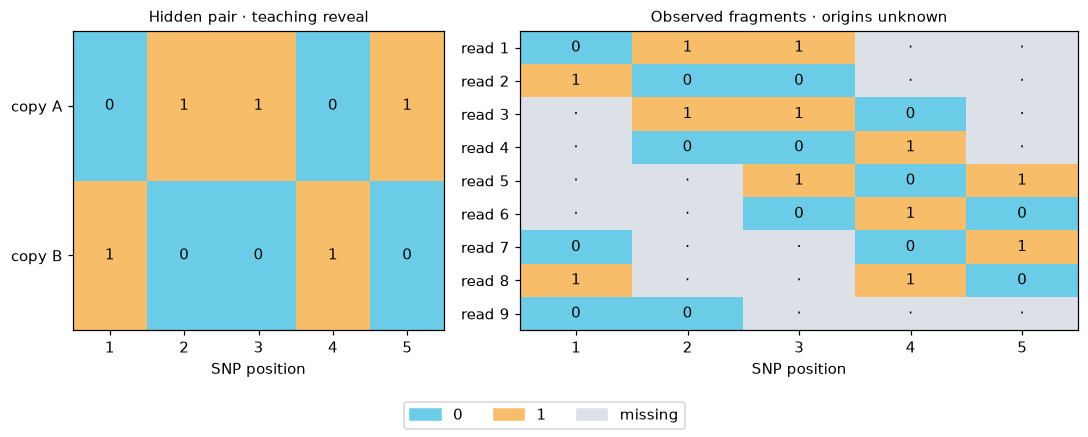

In [81]:
#@title Supplied data and diagrams · expand only if curious
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from collections import deque
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator

# Truth is for this teaching picture only; no scoring/training function receives it.
TEACHING_PAIR = np.array([[0,1,1,0,1], [1,0,0,1,0]])
READS = np.array([[0,1,1,-1,-1], [1,0,0,-1,-1],
                  [-1,1,1,0,-1], [-1,0,0,1,-1],
                  [-1,-1,1,0,1], [-1,-1,0,1,0],
                  [0,-1,-1,0,1], [1,-1,-1,1,0],
                  [0,0,-1,-1,-1]])  # final fragment contradicts 1–2 evidence
N = READS.shape[1]
CYAN, GOLD, GREY = '#6ACCE6', '#F7BD69', '#DCE1E8'
plt.rcParams.update({'figure.dpi':110, 'font.size':10})
def show_reads():
    fig, axes = plt.subplots(1,2,figsize=(10,4),gridspec_kw={'width_ratios':[1,1.5]})
    for ax, data, title, labels in zip(axes, [TEACHING_PAIR,READS],
            ['Hidden pair · teaching reveal','Observed fragments · origins unknown'],
            [['copy A','copy B'], [f'read {i+1}' for i in range(len(READS))]]):
        ax.imshow(data+1,cmap=ListedColormap([GREY,CYAN,GOLD]),vmin=0,vmax=2,aspect='auto')
        ax.set_xticks(range(N),[str(i+1) for i in range(N)]);ax.set_xlabel('SNP position')
        ax.set_yticks(range(len(data)),labels);ax.set_title(title,fontsize=10)
        for (r,c),v in np.ndenumerate(data): ax.text(c,r,'·' if v<0 else str(v),ha='center',va='center')
    fig.legend(handles=[Patch(color=CYAN,label='0'),Patch(color=GOLD,label='1'),
                        Patch(color=GREY,label='missing')],loc='lower center',ncol=3)
    fig.tight_layout(rect=(0,.09,1,1));plt.show()
def show_graph(a,d):
    g=nx.Graph();g.add_nodes_from(range(len(a)))
    fig,ax=plt.subplots(figsize=(6,4));pos=nx.circular_layout(g)
    nx.draw_networkx_nodes(g,pos,ax=ax,node_color=GREY,node_size=650)
    nx.draw_networkx_labels(g,pos,labels={i:str(i+1) for i in g},ax=ax)
    labels={}
    for i,j in itertools.combinations(g,2):
        if a[i,j]+d[i,j]==0: continue
        net=a[i,j]-d[i,j]
        nx.draw_networkx_edges(g,pos,edgelist=[(i,j)],ax=ax,
            edge_color=CYAN if net>0 else GOLD if net<0 else GREY,
            style='solid' if net>0 else 'dashed' if net<0 else 'dotted',
            width=1+abs(net))
        labels[i,j]=f'{int(a[i,j])}/{int(d[i,j])}'
    nx.draw_networkx_edge_labels(g,pos,edge_labels=labels,font_size=8,ax=ax)
    ax.set_title('Same / opposite votes · width = net strength')
    ax.legend(handles=[Patch(color=CYAN,label='same'),Patch(color=GOLD,label='opposite'),
                       Patch(color=GREY,label='tie')],loc='lower center',ncol=3,bbox_to_anchor=(.5,-.12))
    ax.axis('off');fig.tight_layout();plt.show()
def decode_key(key,n):
    bits=str(key).replace(' ','')
    if len(bits)!=n or set(bits)-{'0','1'}: raise ValueError('Expected n measured binary bits.')
    return np.array([int(b) for b in bits[::-1]])
def text(x): return ''.join(map(str,x))  # SNP 1 first, unlike a Qiskit key
# Qiskit displays qubit 0 on the RIGHT; never reverse a physical layout again.
assert np.array_equal(decode_key('00101',5),[1,0,1,0,0])
show_reads()

The right-hand fragments overlap. The last row conflicts with the majority relation between SNPs 1–2.
The picture reveals a synthetic pair for intuition; search uses only the observed matrix.
Swapping copy A and copy B leaves the reconstruction unchanged.

## 2 · Reads become a signed graph
The read `0,1,1` votes **opposite** for 1–2, **same** for 2–3, and **opposite** for 1–3.
One node represents each SNP; repeated observations strengthen an edge. Errors can create minority votes.

**Task A:** return two upper-triangular `n × n` arrays: `a[i,j]` counts same votes, `d[i,j]` opposite votes.
Visit **all co-observed pairs**, including non-adjacent sites. Leave diagonal/lower triangle zero.

<details><summary>Hint 1 · idea</summary>

A read and its complement cast identical pair votes. Ignore missing calls.

</details>

<details><summary>Hint 2 · structure</summary>

Allocate two zero matrices. For each row find observed indices; loop over their combinations of size two and increment the matching matrix.

</details>

In [82]:
def build_evidence(reads):
    n = len(reads[0])
    a = np.zeros((n, n), dtype=int)
    d = np.zeros((n, n), dtype=int)

    for read in reads:
        observed = []
        for i in range(len(read)):
            if read[i] != -1:
                observed.append(i)

        for p in range(len(observed)):
            for q in range(p + 1, len(observed)):
                i = observed[p]
                j = observed[q]

                if read[i] == read[j]:
                    a[i, j] += 1
                else:
                    d[i, j] += 1

    return a, d

Evidence checks passed. Labels are same/opposite counts, not probability of truth.


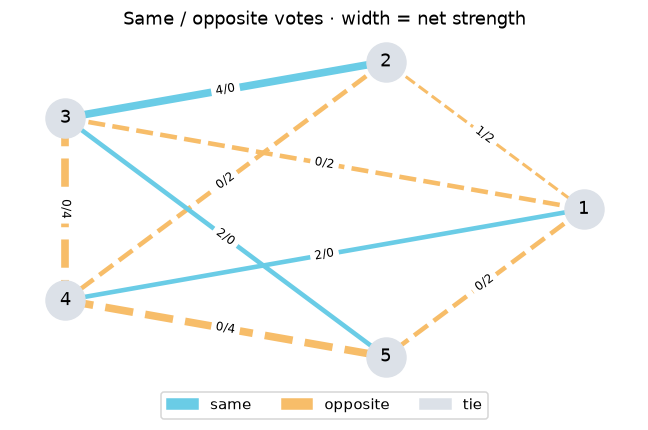

In [83]:
tiny=np.array([[0,1,1],[1,0,0],[0,0,-1]])
ta,td=build_evidence(tiny)
assert np.array_equal(ta,[[0,1,0],[0,0,2],[0,0,0]]), 'Check same votes and upper triangle.'
assert np.array_equal(td,[[0,2,2],[0,0,0],[0,0,0]]), 'Count all observed pairs, skipping missing calls.'
A,D=build_evidence(READS)
assert A.shape==D.shape==(N,N)
assert np.all(np.tril(A)==0) and np.all(np.tril(D)==0)
print('Evidence checks passed. Labels are same/opposite counts, not probability of truth.')
show_graph(A,D)

## 3 · Define one cost, then enumerate
A candidate `x` specifies one haplotype; the other is `1−x`.
Pay one penalty for every pair vote the candidate contradicts:
$$C(x)=\sum_{i<j}\left(A_{ij}[x_i\ne x_j]+D_{ij}[x_i=x_j]\right).$$
For the tiny matrix above, score `011` and `001` by hand before coding.
*Our scores:* 1 + 0 + 1 = 2

**Task B:** implement this compact pairwise cost. Lower is better **under this model**.
Longer reads generate more pair votes; those votes are correlated. This objective is not biological truth.

<details><summary>Hint 1 · idea</summary>

Equal candidate bits contradict opposite votes; different bits contradict same votes.

</details>

<details><summary>Hint 2 · structure</summary>

Loop over i<j, adding a[i,j] if the bits differ, otherwise d[i,j].

</details>

In [84]:
def pairwise_cost(x, a, d):
    cost = 0
    for j in range(len(x)):
        for i in range(j):
            if x[i] != x[j]:
                cost += a[i, j]
            else:
                cost += d[i, j]
    return cost

In [85]:
assert pairwise_cost([0,1,1],ta,td)==1, 'Compare each pair against its votes.'
assert pairwise_cost([0,0,1],ta,td)==4, 'Count the minority votes too.'
for x in itertools.product([0,1],repeat=N):
    assert pairwise_cost(x,A,D)==pairwise_cost(1-np.array(x),A,D), 'Copy names must not matter.'
print('Manual-score and complement-symmetry checks passed.')

Manual-score and complement-symmetry checks passed.


**Task C · classical reference:** enumerate all `2**N = 32` patterns and their costs.
Return `(states, costs)`, with one row per state. Keep both complementary labels: they are equivalent,
but retaining all states makes comparison with the quantum distribution straightforward.
Exact enumeration certifies this tiny model; its exponential cost limits larger problems.

<details><summary>Hint 1 · idea</summary>

Enumeration must include every bit pattern, not only your guess.

</details>

<details><summary>Hint 2 · structure</summary>

Use itertools.product([0,1], repeat=len(a)), convert to a NumPy array, then score each row.

</details>

In [86]:
def exact_reference(a, d):
    states = np.array(list(itertools.product([0, 1], repeat=len(a))), dtype=int)
    costs = np.array([pairwise_cost(x, a, d) for x in states], dtype=float)
    return states, costs

In [87]:
states,costs=exact_reference(A,D)
assert states.shape==(2**N,N) and costs.shape==(2**N,), 'Return all states and one cost per row.'
assert set(map(tuple,states))==set(itertools.product([0,1],repeat=N)), 'Missing or repeated states.'
assert np.allclose(costs,[pairwise_cost(x,A,D) for x in states]), 'Costs must match states.'
OPTIMUM=float(costs.min())
display(pd.DataFrame({'candidate (SNP 1 first)':[text(x) for x in states], 'cost':costs})
        .sort_values('cost',kind='stable').reset_index(drop=True))
print('Exact minimum:',OPTIMUM,'| optimal labels:',sum(np.isclose(costs,OPTIMUM)))

,candidate (SNP 1 first),cost
0,01101,1.0
1,10010,1.0
2,00010,8.0
3,00101,8.0
4,11010,8.0
5,11101,8.0
6,01100,9.0
7,10011,9.0
8,00001,12.0
9,00011,12.0


Exact minimum: 1.0 | optimal labels: 2


## 4 · The same graph becomes Ising
For one edge with **three same votes and one opposite vote**, equal bits cost 1, different bits cost 3.
Let $z_i=1-2x_i$. The edge energy $2-z_i z_j$ gives exactly those values: a **negative coupling favors same**.

In general,
$$H=c_0 I+\sum_{i<j}J_{ij}Z_iZ_j,\qquad
J_{ij}=(D_{ij}-A_{ij})/2,\quad c_0=\sum_{i<j}(A_{ij}+D_{ij})/2.$$
**Task D:** implement couplings/offset and classical Ising energy. Use each pair once.
Verify equality for **every** tiny state before constructing gates.

<details><summary>Hint 1 · idea</summary>

The Z eigenvalues are +1 for bit 0 and −1 for bit 1.

</details>

<details><summary>Hint 2 · structure</summary>

Return (d-a)/2 and sum(a+d)/2. Energy is the offset plus the upper-triangle sum of J[i,j]*z[i]*z[j].

</details>

In [88]:
def ising_from_evidence(a, d):
    couplings = (d - a) / 2
    offset = 0
    for i in range(len(a)):
        for j in range(i + 1, len(a)):
            offset += (a[i, j] + d[i, j]) / 2
    return couplings, offset


def ising_energy(x, couplings, offset):
    z = 1 - 2 * np.asarray(x)
    energy = offset

    for i in range(len(x)):
        for j in range(i + 1, len(x)):
            energy += couplings[i, j] * z[i] * z[j]

    return energy

In [89]:
J,offset=ising_from_evidence(A,D)
assert np.allclose(J,(D-A)/2), 'Negative coupling favors same; use upper triangle only.'
assert np.isclose(offset,(A+D).sum()/2), 'Keep the constant for reported energies.'
assert all(np.isclose(ising_energy(x,J,offset),c) for x,c in zip(states,costs)), 'Check spin conversion and pair counting.'
print('Ising equals graph cost on all',2**N,'states. Couplings:')
display(pd.DataFrame(J,index=range(1,N+1),columns=range(1,N+1)))

Ising equals graph cost on all 32 states. Couplings:


,1,2,3,4,5
1,0.0,0.5,1.0,-1.0,1.0
2,0.0,0.0,-2.0,1.0,0.0
3,0.0,0.0,0.0,2.0,-1.0
4,0.0,0.0,0.0,0.0,2.0
5,0.0,0.0,0.0,0.0,0.0


## 5 · Construct QAOA, then train locally
**$|+\rangle$ initialization → cost layer → mixer layer → repeat $p$ times → measurement**

The cost layer changes phases; the mixer combines amplitudes. Interference reshapes the sampling
distribution. A classical optimizer adjusts the angles to lower average energy. There is no assumed quantum advantage.

**Task E:** build the **complete unmeasured ansatz**, returning `(qc, theta, scale)`.
Initialize every qubit with H. For each layer use `rzz(2*gamma*J[i,j]/scale, i, j)` on nonzero pairs,
then `rx(2*beta)` on every qubit. `theta[:p]` are gammas and `theta[p:]` betas.
Use `scale=max(1, max(abs(J)))`. It rescales circuit angles, not the reported cost.

Qiskit uses $RZZ(t)=e^{-itZZ/2}$ and $RX(t)=e^{-itX/2}$. The constant offset only adds a global phase;
this model has no local fields and needs no RZ gates. Measurements belong in a **later copy**.

<details><summary>Hint 1 · idea</summary>

Cost and mixer must alternate within each layer. Do not measure the optimization circuit.

</details>

<details><summary>Hint 2 · structure</summary>

Create QuantumCircuit(n) and ParameterVector("theta",2*p). H all qubits; loop layers, then pairs for RZZ and qubits for RX. Return circuit, parameters and positive scale.

</details>

In [90]:
def make_qaoa(j, p=1):
    J = np.asarray(j, dtype=float)
    n = J.shape[0]
    scale = float(max(1, np.max(np.abs(J))))

    theta = ParameterVector("theta", 2 * p)
    #primele p val gamma, urmatoarele p theta
    gammas, betas = theta[:p], theta[p:]

    qc = QuantumCircuit(n)
    # + state
    qc.h(range(n))

    #p layers
    for layer in range(p):
        # pe toate perechile a b, a<b, unde J(a,b)!=0 pun poarta rzz
        for a in range(n):
            for b in range(a + 1, n):     
                w = J[a, b]
                if w != 0:
                    qc.rzz(2 * gammas[layer] * w / scale, a, b)
        for q in range(n):
        # pun rx pe toti qubitii
            qc.rx(2 * betas[layer], q)

    return qc, theta, scale

In [91]:
P=2
ansatz,theta,scale=make_qaoa(J,P)
assert ansatz.num_qubits==N and ansatz.num_clbits==0, 'Return an unmeasured circuit.'
assert len(theta)==2*P and ansatz.num_parameters==2*P
assert ansatz.count_ops().get('rzz',0)==P*np.count_nonzero(J), 'One RZZ per active pair per layer.'
assert ansatz.count_ops().get('rx',0)==P*N and ansatz.count_ops().get('h',0)==N
assert np.isclose(scale,max(1,np.abs(J).max()))


def bind(values): return ansatz.assign_parameters(dict(zip(theta,values)))

def probabilities(values): return Statevector.from_instruction(bind(values)).probabilities()

# Statevector index k uses qubit i = (k >> i) & 1; enumeration above has a different row order.
basis_states=np.array([[(k>>i)&1 for i in range(N)] for k in range(2**N)])

energy_array=np.array([ising_energy(x,J,offset) for x in basis_states])

assert np.allclose(probabilities(np.zeros(2*P)),1/2**N), 'H initialization should be uniform.'
print(ansatz.draw(output='text'))

     ┌───┐                                                        »
q_0: ┤ H ├─■──────────────────■────────────────■──────────────────»
     ├───┤ │ZZ(0.5*theta[0])  │                │                  »
q_1: ┤ H ├─■──────────────────┼────────────────┼──────────────────»
     ├───┤                    │ZZ(1*theta[0])  │                  »
q_2: ┤ H ├────────────────────■────────────────┼──────────────────»
     ├───┤                                     │ZZ((-1)*theta[0]) »
q_3: ┤ H ├─────────────────────────────────────■──────────────────»
     ├───┤                                                        »
q_4: ┤ H ├────────────────────────────────────────────────────────»
     └───┘                                                        »
«                                          ┌────────────────┐                  »
«q_0: ─────────────────────■───────────────┤ Rx(2*theta[2]) ├──────────────────»
«                          │               └────────────────┘┌────────────────┐»
«q_1: ─■─

**Task F:** implement the probability-weighted expected energy used by the supplied optimizer:
`sum(probability[k] * energy[k])`. Use deterministic statevector probabilities during training,
so shot noise does not obscure what the optimizer is doing. Final measurements will use fresh finite shots.
This training simulates all amplitudes and is intended only for small instances.

<details><summary>Hint 1 · idea</summary>

Minimize the mean across the whole distribution, not its lowest-energy sample.

</details>

<details><summary>Hint 2 · structure</summary>

Compute probabilities(values), then its dot product with energy_array.

</details>

In [92]:
def expected_energy(values):
    return float(probabilities(values) @ energy_array)

In [93]:
#@title Supplied optimizer and fresh final sampling · statevector training is local
assert np.isclose(expected_energy(np.zeros(2*P)),energy_array.mean()), 'Uniform mean must average all states.'
rng=np.random.default_rng(71)
starts=[rng.uniform(0,np.pi,2*P) for _ in range(2)]
trials=[minimize(expected_energy,start,method='COBYLA',options={'maxiter':90}) for start in starts]
trained=min(trials,key=lambda result:result.fun)
fixed=bind(trained.x)
measured=fixed.copy();measured.measure_all()
SHOTS=2048
RUN_BACKEND = RUN_NOISE_SIMULATOR = RUN_PASS_MANAGER = None
if RUN_MODE != 'simulator':
    RUN_BACKEND = get_ibm_service().backend(BACKEND_NAME)
    if N > RUN_BACKEND.num_qubits:
        raise ValueError(f'The {N}-SNP instance exceeds {RUN_BACKEND.name} capacity ({RUN_BACKEND.num_qubits} qubits).')
    RUN_PASS_MANAGER = generate_preset_pass_manager(
        backend=RUN_BACKEND, optimization_level=2, seed_transpiler=71)
    if RUN_MODE == 'simulator_noise':
        RUN_NOISE_SIMULATOR = AerSimulator.from_backend(
            RUN_BACKEND, method='matrix_product_state', max_parallel_threads=1)

def run_selected(circuit, seed=72):
    if RUN_MODE == 'simulator':
        counts = AerSimulator(max_parallel_threads=1).run(
            circuit, shots=SHOTS, seed_simulator=seed).result().get_counts()
        return counts, circuit.depth()
    isa = RUN_PASS_MANAGER.run(circuit)
    if RUN_MODE == 'simulator_noise':
        counts = RUN_NOISE_SIMULATOR.run(
            isa, shots=SHOTS, seed_simulator=seed).result().get_counts()
    else:
        from qiskit_ibm_runtime import SamplerV2
        job = SamplerV2(mode=RUN_BACKEND).run([isa], shots=SHOTS)
        print(f'Real backend job: {job.job_id()} | backend: {RUN_BACKEND.name} | shots: {SHOTS}', flush=True)
        counts = job.result()[0].data.meas.get_counts()
    return counts, isa.depth()

# Keep an ideal reference for direct comparison with noisy or hardware samples.
ideal_counts=AerSimulator(max_parallel_threads=1).run(
    measured, shots=SHOTS, seed_simulator=72).result().get_counts()
assert sum(ideal_counts.values())==SHOTS
print('Statevector evaluations:',sum(t.nfev for t in trials),'| final expectation:',round(trained.fun,3))
print('Selected mode:',RUN_MODE,'| backend:',BACKEND_NAME,'| ideal reference shots:',SHOTS)
print('The optimizer trains locally with exact statevector probabilities; final samples follow RUN_MODE.')

qiskit_runtime_service._discover_account:WARNING:2026-11-07 19:55:11,722: Loading account with the given token. A saved account will not be used.


Statevector evaluations: 180 | final expectation: 2.482
Selected mode: simulator_noise | backend: ibm_aachen | ideal reference shots: 2048
The optimizer trains locally with exact statevector probabilities; final samples follow RUN_MODE.


In [94]:
#@title Supplied display helpers · you choose the comparison below

def sample_summary(name,counts,depth):
    scored=[(pairwise_cost(decode_key(k,N),A,D),k,v) for k,v in counts.items()]
    best_cost,best_key,_=min(scored)
    shots=sum(counts.values())
    return {'method':name, 'selected candidate':text(decode_key(best_key,N)),
            'best cost':best_cost, 'mean cost':sum(c*v for c,k,v in scored)/shots,
            'optimum frequency':sum(v for c,k,v in scored if np.isclose(c,OPTIMUM))/shots,
            'shots':shots, 'depth':depth}
def show_comparison(counts,metric='mean cost'):
    if metric not in ['mean cost','optimum frequency']: raise ValueError('Choose mean cost or optimum frequency.')
    rows=[{'method':'exact (all states)','selected candidate':text(states[np.argmin(costs)]),
           'best cost':OPTIMUM,'mean cost':np.nan,'optimum frequency':np.nan,'shots':0,'depth':0},
          sample_summary('QAOA',counts,measured.depth())]
    display(pd.DataFrame(rows).round(3))
    uniform=float(costs.mean()) if metric=='mean cost' else float(np.mean(np.isclose(costs,OPTIMUM)))
    fig,axes=plt.subplots(1,2,figsize=(10,3.4))
    vals=[uniform,rows[1][metric]]
    bars=axes[0].bar(['uniform (exact)','QAOA samples'],vals,color=[GREY,CYAN])
    axes[0].bar_label(bars,fmt='%.3f',padding=3);axes[0].set_title(metric)
    axes[0].set_ylim(0,max(vals)*1.25+.05)
    sampled_costs=[pairwise_cost(decode_key(k,N),A,D) for k in counts]
    axes[1].hist(sampled_costs,weights=list(counts.values()),bins=np.arange(costs.min()-.5,costs.max()+1.5),color=CYAN)
    axes[1].axvline(OPTIMUM,color='#14243A',linestyle='--',label='exact minimum')
    axes[1].set(xlabel='graph cost',ylabel='shots',title='Whole final distribution');axes[1].legend()
    fig.tight_layout();plt.show()

**Task G · ideal reference comparison:** this section always shows the ideal-Aer reference. Backend-noise and real-hardware samples are shown in the following sections. Call `show_comparison(ideal_counts, metric=...)`,
choosing **mean cost** or **optimum frequency**. It displays exact certification, QAOA results and a uniform null comparison.

*Why this metric?* We want to recover the single best phasing, and exact enumeration already certifies the true model minimum (OPTIMUM), so the question that matters is how often finite sampling from the trained circuit actually lands on that minimum. That is optimum frequency, not average sample quality.  
*Compared with uniform sampling, what did QAOA change?* QAOA concentrated probability on low-cost states: its optimum frequency sits well above the uniform-null baseline of 1/2^N, and the histogram is skewed toward the dashed exact-minimum line rather than spread flat across all costs.  
*Did its best observed cost reach the exact minimum? Is a typical sample also good?* Yes - the QAOA row's best cost matches the exact row's OPTIMUM. A typical sample is better than random but not always optimal, which is why best cost and mean cost differ and optimum frequency is below 1.  
*What can one tiny instance and one final sample set establish?* Only that the pipeline works end-to-end on this 5-SNP toy. It does not establish biological accuracy, generalization to larger instances, or any quantum advantage.

A mean cost summarizes typical quality; optimum frequency measures how often the best model score is sampled.
Neither establishes biological accuracy, generalization or quantum advantage.

<details><summary>Hint 1 · idea</summary>

Pick a metric to answer your question, not just the most flattering number.

</details>

<details><summary>Hint 2 · structure</summary>

For typical quality choose metric="mean cost"; for repeated minimum finding choose metric="optimum frequency". Explain both the displayed table and distribution.

</details>

,method,selected candidate,best cost,mean cost,optimum frequency,shots,depth
0,exact (all states),01101,1.0,NaN,NaN,0,0
1,QAOA,10010,1.0,2.434,0.893,2048,16


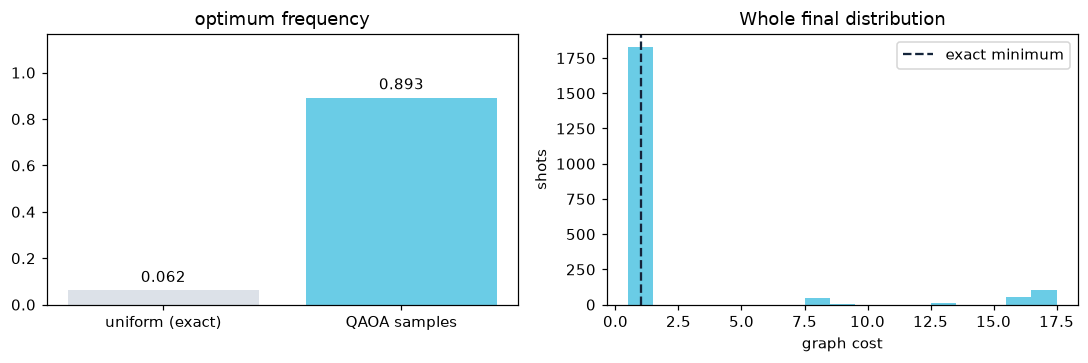

In [95]:
show_comparison(ideal_counts, metric='optimum frequency')
#0.893 p=2
#0.55 p=3

## 5b · Warm-start and multi-angle QAOA (same instance, p = 2)

Two variants of QAOA on the same five-SNP instance at p = 2, compared with vanilla QAOA. Their angle training uses exact local statevector probabilities; final samples follow the opening `RUN_MODE`. In `real_backend` mode, this cell submits three jobs (one per circuit), in addition to the main hardware run later.

- **Warm-start QAOA** (Egger–Mareček–Woerner): replace the uniform `H`
  initialisation with a biased product state `∏ RY(θᵢ)|0⟩` built from a
  relaxed candidate `c`, and use the matching `RY(θ)`-conjugated mixer so that
  state is the mixer ground state. Trained with **100 COBYLA iterations, 5
  starts**.
- **Multi-angle QAOA** (ma-QAOA, Herrman et al.): identical gate structure to
  vanilla — so identical two-qubit-gate count — but every RZZ and every RX gets
  its own angle (here `p·(9 active couplings + 5) = 28` parameters vs 4). The
  extra cost is purely classical; it needs more optimiser effort, so it is
  trained with **500 COBYLA iterations, 5 starts**.


,method,budget (iter x starts),params,nfev,optimum frequency,mean cost,depth,two-qubit gates,final expectation
0,vanilla p=2,100 x 5,0,446,0.800,3.316,166,18,2.185
1,warm-start p=2,100 x 5,0,500,0.685,4.651,173,18,3.557
2,ma-QAOA p=2,500 x 5,28,2500,0.884,2.205,168,18,1.006


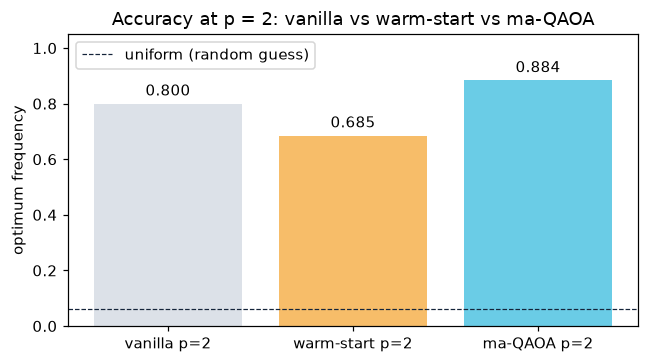

ma-QAOA keeps the same two-qubit-gate count as vanilla p=2; its extra cost is the larger classical optimisation (nfev).


In [96]:
#@title Warm-start QAOA (100x5) and ma-QAOA (500x5) vs vanilla p=2
from qiskit.circuit import Parameter, ParameterVector

P2 = 2  # both variants at depth p = 2

# --- shared exact-statevector training (COBYLA, several random restarts) ------
def train_ansatz(ansatz, params, maxiter, n_starts, seed=71):
    def bind_vals(values):
        return ansatz.assign_parameters(dict(zip(params, values)))
    def energy(values):
        return float(Statevector.from_instruction(bind_vals(values)).probabilities()
                     @ energy_array)
    rng_local = np.random.default_rng(seed)
    starts = [rng_local.uniform(0, np.pi, len(params)) for _ in range(n_starts)]
    trials = [minimize(energy, s, method='COBYLA', options={'maxiter': maxiter})
              for s in starts]
    best = min(trials, key=lambda r: r.fun)
    circ = bind_vals(best.x).copy()
    circ.measure_all()
    return circ, best, int(sum(t.nfev for t in trials))

def counts_of(circ, seed):
    return run_selected(circ, seed)

# --- warm-start QAOA ----------------------------------------------------------
def warm_start_qaoa(n, J, c, p, eps):
    J = np.asarray(J, dtype=float)
    c = np.clip(c, eps, 1 - eps)
    theta = 2 * np.arcsin(np.sqrt(c))
    scale = float(max(1, np.max(np.abs(J))))
    gam = [Parameter(f'g{k}') for k in range(p)]
    bet = [Parameter(f'b{k}') for k in range(p)]
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(theta[i], i)                       # warm-start state
    for k in range(p):
        for i in range(n):
            for j in range(i + 1, n):
                if J[i, j] != 0:
                    qc.rzz(2 * gam[k] * J[i, j] / scale, i, j)
        for i in range(n):                       # warm-start mixer
            qc.ry(-theta[i], i)
            qc.rz(-2 * bet[k], i)
            qc.ry(theta[i], i)
    return qc, list(gam) + list(bet)

# ma-QAOA: every RZZ and RX gets its own angle (same gates as vanilla) ----------
def make_ma_qaoa(J, p):
    J = np.asarray(J, dtype=float); n = J.shape[0]
    scale = float(max(1, np.max(np.abs(J))))
    active = [(a, b) for a in range(n) for b in range(a + 1, n) if J[a, b] != 0]
    per_layer = len(active) + n
    theta = ParameterVector('ma', p * per_layer)
    qc = QuantumCircuit(n); qc.h(range(n))
    for layer in range(p):
        base = layer * per_layer
        for idx, (a, b) in enumerate(active):
            qc.rzz(2 * theta[base + idx] * J[a, b] / scale, a, b)
        for q in range(n):
            qc.rx(2 * theta[base + len(active) + q], q)
    return qc, list(theta)

# --- vanilla p=2 baseline (100x5), trained the same way for a fair row --------
van_ansatz, van_theta, _ = make_qaoa(J, P2)
van_circ, van_best, van_nfev = train_ansatz(van_ansatz, list(van_theta), 100, 5)

# --- warm-start p=2 (100 iterations, 5 starts) --------------------------------
# Instance is complement-symmetric, so seed c from one exact minimiser's bits.
c_seed = states[np.isclose(costs, OPTIMUM)][0].astype(float)
ws_ansatz, ws_params = warm_start_qaoa(N, J, c_seed, P2, eps=0.25)
ws_circ, ws_best, ws_nfev = train_ansatz(ws_ansatz, ws_params, 100, 5)

# --- ma-QAOA p=2 (500 iterations, 5 starts) -----------------------------------
ma_ansatz, ma_params = make_ma_qaoa(J, P2)
ma_circ, ma_best, ma_nfev = train_ansatz(ma_ansatz, ma_params, 500, 5)

def two_qubit_gates(qc):
    return sum(it.operation.num_qubits == 2 for it in qc.data)

rows = []
for seed, (name, circ, best, nfev, budget) in enumerate([
        ('vanilla p=2',    van_circ, van_best, van_nfev, '100 x 5'),
        ('warm-start p=2', ws_circ,  ws_best,  ws_nfev,  '100 x 5'),
        ('ma-QAOA p=2',    ma_circ,  ma_best,  ma_nfev,  '500 x 5')]):
    counts, sampled_depth = counts_of(circ, 74 + seed)
    r = sample_summary(name, counts, sampled_depth)
    r['budget (iter x starts)'] = budget
    r['params'] = circ.num_parameters if name != 'ma-QAOA p=2' else len(ma_params)
    r['nfev'] = nfev
    r['two-qubit gates'] = two_qubit_gates(circ)
    r['final expectation'] = round(float(best.fun), 3)
    rows.append(r)

cmp = pd.DataFrame(rows)[['method', 'budget (iter x starts)', 'params', 'nfev',
                          'optimum frequency', 'mean cost', 'depth',
                          'two-qubit gates', 'final expectation']]
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
display(cmp.round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(cmp['method'], cmp['optimum frequency'], color=[GREY, GOLD, CYAN])
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.axhline(float(np.mean(np.isclose(costs, OPTIMUM))), color='#14243A', ls='--',
           lw=.8, label='uniform (random guess)')
ax.set_ylim(0, 1.05); ax.set_ylabel('optimum frequency'); ax.legend()
ax.set_title('Accuracy at p = 2: vanilla vs warm-start vs ma-QAOA')
fig.tight_layout(); plt.show()
print('ma-QAOA keeps the same two-qubit-gate count as vanilla p=2; its extra '
      'cost is the larger classical optimisation (nfev).')


## 6 · Fixed angles, different hardware realization
The opening `RUN_MODE` controls every final sampling cell: `simulator` uses ideal Aer, `simulator_noise` uses local Aer with the selected backend's calibration noise, and `real_backend` submits circuits to that backend. Angle optimization in this lab remains local statevector optimization; the selected mode controls final measurement sampling.

The noisy simulator and hardware circuits are transpiled for the selected backend. Compare their measured distributions with the ideal reference from the previous section.

In [97]:
#@title Backend-calibrated local noise simulation (no QPU submission)
if RUN_MODE == 'simulator_noise':
    noisy_counts, noisy_depth = run_selected(measured, seed=73)
    rows=[sample_summary('ideal Aer reference',ideal_counts,measured.depth()),
          sample_summary(f'{RUN_BACKEND.name} calibration noise (local Aer)',noisy_counts,noisy_depth)]
    display(pd.DataFrame(rows).round(3))
    print(f'Local Aer simulation using {RUN_BACKEND.name} calibration only; no QPU job submitted. Shots per distribution: {SHOTS}')
elif RUN_MODE == 'simulator':
    print('Ideal Aer selected; no backend calibration was fetched.')
else:
    print('Real backend selected; this cell does not submit a job. The hardware run is in the next section.')

,method,selected candidate,best cost,mean cost,optimum frequency,shots,depth
0,ideal Aer reference,10010,1,2.434,0.893,2048,16
1,ibm_aachen calibration noise (local Aer),10010,1,3.511,0.790,2048,169


Local Aer simulation using ibm_aachen calibration only; no QPU job submitted. Shots per distribution: 2048


### Hardware interpretation
Compare the ideal reference with the selected-mode sample. For local noise, Aer approximates gate, relaxation, and readout errors from backend calibration data; it does not model every device effect or calibration drift. What changed after routing and noise? Can one sample separate noise from shot variation? Which layout/depth experiment would help?

### Optional real IBM hardware run
In `real_backend` mode, the next cell submits one main QPU job. The earlier warm-start/multi-angle comparison submits three additional jobs when that cell is run. All use the configured backend and 2,048 shots per circuit. Credentials load from `.env` or process environment variables; save each printed job ID before waiting for results.

The main run uses the same five-SNP input and trained angles as the local simulation.

References: [IBM SamplerV2](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/0.47/sampler-v2), [Sampler results](https://quantum.cloud.ibm.com/docs/en/guides/sampler-input-output), [bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

In [98]:
#@title Optional real IBM submission
real_counts=None
if RUN_MODE == 'real_backend':
    real_counts, real_depth = run_selected(measured, seed=75)
    display(pd.DataFrame([sample_summary('real IBM hardware',real_counts,real_depth)])[
        ['method','mean cost','optimum frequency','depth','shots']].round(3))
else:
    print('Real backend not selected; no QPU job submitted.')

Real backend not selected; no QPU job submitted.


---
# Shared foundation complete — your team’s investigation starts here.

Running this notebook is a learning achievement. Competitive hackathon work requires an original investigation
**beyond** the supplied workflow. Choose one direction:

| Direction | A focused starting question |
|---|---|
| Evidence/objective | Which reads or relationships should count more? Does pruning simplify circuits? |
| QAOA/search | How do depth, starts, optimizer or mixer affect the distribution? |
| Hardware/resources | Do coupling-aware SNP ordering, layout or routing reduce gates and noise? |
| Information limits | When do missing connections make relative phase unknowable? |

**Optional twist:** full-read Minimum Error Correction (MEC) counts how many individual read calls must change
to fit either copy. It can rank candidates differently from this pairwise cost. Neither objective guarantees
biological truth. Investigating the discrepancy is an extension, not another required core implementation.

## Our investigation workspace
**One focused question:** …  
**Prediction:** …  
**One proposed change:** …  
**One fair comparison (baseline, controls, metric, resources):** …  
**Evidence / code / figure:** …  
**One conclusion, limitation or failure:** …

Keep data and parameters matched when testing hardware effects. Recompute the exact reference after changing
evidence. For broader claims, repeat across relevant instances/seeds and show failures as well as successes.

## Final disclosure and submission
Submit your notebook/code with outputs and a short presentation showing your question, change, fair comparison,
evidence and conclusion/limitation. Real-hardware claims need backend, shots and job IDs.
Judging uses presentations and submitted evidence, with manual/AI-assisted review; there is no hidden leaderboard.

**Which fallback/reference implementations did you use?** …  
**What did your team implement or change?** …  
**What is your original contribution?** …

## 7 · Investigation · Does pruning weak edges help or destroy information?

An edge whose net weight A−D is near zero carries little preference, so it is
tempting to drop it. But removing an edge can disconnect the graph, and once the
active SNPs split into k components, flipping any whole component leaves the
pairwise score unchanged — at least 2^(k−1) relative orientations tie, and no
optimizer can recover a relationship the model no longer contains.

**Question.** Does dropping weak or suspicious edges improve phasing, and when
does it destroy information instead?

**Fair comparison.** For each dataset we build the full graph once, then apply
each pruning rule to that same graph (paired). Every pruned candidate is rescored
on the **full** model and against truth — never by its own smaller cost, which is
trivially lower. Tied minima are scored by the honest random-pick accuracy
1/|set|, never counted as free wins. We average over several random seeds.

Rules (one at a time): net-strength |A−D| < t · support A+D < m · tie A==D ·
top-k strongest · bridge removal. Controls: drop the same number of edges at
random, and drop the *strongest* edges instead of the weakest.


In [99]:
def edge_table(a, d):
    n = len(a)
    edges = []
    for i, j in itertools.combinations(range(n), 2):
        total = float(a[i, j] + d[i, j])
        if total:
            edges.append({'i': i, 'j': j, 'A': float(a[i, j]), 'D': float(d[i, j]),
                          'net': float(a[i, j] - d[i, j]), 'total': total})
    edges.sort(key=lambda e: abs(e['net']), reverse=True)
    return edges

# A tie edge (A==D, net==0) carries zero coupling (its Ising weight (D-A)/2 is 0),
# so it can neither hold two SNPs in a relative orientation nor split the graph.
# Connectivity is a property of the COUPLING graph, so we count active edges only.
# Otherwise a tie looks like it "connects" in the baseline and "disconnects" the
# moment it is pruned, inflating k and the disconnected fraction for no reason.
def active_edges(edges):
    return [e for e in edges if e['net'] != 0]

#nr componente conexe (pe graful activ) si nodurile izolate
def components(n, edges, active_only=True):
    use = active_edges(edges) if active_only else edges
    adj = [set() for _ in range(n)]
    for e in use:
        adj[e['i']].add(e['j'])
        adj[e['j']].add(e['i'])

    seen = [False]*n
    k = 0
    for s in range(n):
        if seen[s] or not adj[s]:
            continue
        k += 1
        seen[s] = True
        q = deque([s])
        while q:
            u = q.popleft()
            for v in adj[u]:
                if not seen[v]:
                    seen[v] = True
                    q.append(v)

    isolated = [v for v in range(n) if not adj[v]]
    return k, isolated

#nr blocuri conexe (pe graful activ), numarand si nodurile izolate
def n_blocks(n, edges):
    use = active_edges(edges)
    adj = [set() for _ in range(n)]
    for e in use:
        adj[e['i']].add(e['j'])
        adj[e['j']].add(e['i'])

    seen = [False]*n
    blocks = 0
    for s in range(n):
        if seen[s]:
            continue
        blocks += 1
        seen[s] = True
        q = deque([s])
        while q:
            u = q.popleft()
            for v in adj[u]:
                if not seen[v]:
                    seen[v] = True
                    q.append(v)
    return blocks

# fiecare regula -> (kept, dropped), threshold t/m/k
# random + strong sanity checks (random da drop la n muchii random, strong da drop la cele mai strong k muchii)
# mstforest = padure de acoperire de greutate maxima pe |A-D| (pastreaza conectivitatea)
def prune(a, d, rule, threshold=None, rng=None):
    edges = edge_table(a, d); n = len(a)
    if rule == 'none':
        return list(edges), []
    if rule == 'net':
        return ([e for e in edges if abs(e['net']) >= threshold],
                [e for e in edges if abs(e['net']) <  threshold])
    if rule == 'support':
        return ([e for e in edges if e['total'] >= threshold],
                [e for e in edges if e['total'] <  threshold])
    if rule == 'tie':
        return ([e for e in edges if e['A'] != e['D']],
                [e for e in edges if e['A'] == e['D']])
    if rule == 'topk':
        return edges[:threshold], edges[threshold:]
    if rule == 'mstforest':
        # Kruskal pe muchiile active (deja sortate desc dupa |net|): adaug muchia
        # cea mai puternica care uneste doua componente diferite. Pastreaza cel
        # mult n-1 muchii, fara cicluri, si exact conectivitatea grafului activ.
        parent = list(range(n))
        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]; x = parent[x]
            return x
        keep = []
        for e in active_edges(edges):
            ri, rj = find(e['i']), find(e['j'])
            if ri != rj:
                parent[ri] = rj; keep.append(e)
        kept_ids = {id(e) for e in keep}
        drop = [e for e in edges if id(e) not in kept_ids]
        return keep, drop
    if rule == 'bridge':
        keep, drop = [], []
        for e in edges:
            without = [x for x in edges if x is not e]
            (drop if n_blocks(n, without) > n_blocks(n, edges) else keep).append(e)
        return keep, drop
    if rule == 'random':
        idx = set(rng.permutation(len(edges))[:int(threshold)].tolist())
        return ([e for i, e in enumerate(edges) if i not in idx],
                [e for i, e in enumerate(edges) if i in idx])
    if rule == 'strong':
        k = int(threshold); return edges[k:], edges[:k]
    raise ValueError(rule)

#din dict inapoi in matrice
def matrices_from_edges(n, edges):
    a = np.zeros((n, n), dtype=float)
    d = np.zeros((n, n), dtype=float)
    for e in edges:
        a[e['i'], e['j']] = e['A']
        d[e['i'], e['j']] = e['D']
    return a, d


def hamming_phased(x, truth):
    x = np.asarray(x)
    truth = np.asarray(truth)
    dd = int(np.sum(x != truth))
    return min(dd, len(x) - dd)

# minimele modelului (mod complement), plus costurile exacte pentru rescoring
def minima_reps(a, d):
    states, costs = exact_reference(a, d)
    opt = float(costs.min())
    reps = set()
    for s in states[np.isclose(costs, opt)]:
        s = s if s[0] == 0 else 1 - s
        reps.add(tuple(int(b) for b in s))
    return sorted(reps), opt

def random_pick_accuracy(reps, truth):
    m = sum(hamming_phased(r, truth) == 0 for r in reps)
    return m / len(reps) if reps else 0.0

# un candidat pruned e "corect fata de modelul complet" daca minimul lui ramane
# minim al modelului complet -- il reevaluam pe modelul COMPLET, nu pe cel pruned
def pruned_min_is_full_min(a_full, d_full, reps_pruned):
    states, costs = exact_reference(a_full, d_full)
    opt = float(costs.min())
    full_min = {tuple(int(b) for b in (s if s[0] == 0 else 1 - s))
                for s in states[np.isclose(costs, opt)]}
    return set(reps_pruned).issubset(full_min)


### The motivating case (illustrative numbers)

| Pair | A | D | net A−D | Kept at t=2? |
|------|---|---|---------|--------------|
| 1-2 | 4 | 0 | 4 | Yes |
| 2-3 | 3 | 1 | 2 | Yes |
| 3-4 | 1 | 0 | 1 | No |
| 4-5 | 3 | 1 | 2 | Yes |

Pruning at t=2 removes only edge 3-4. The graph splits into {1,2,3} and {4,5}, so
k=2 and at least 2^(2−1)=2 orientations tie. Edge 3-4 had just one vote so it
looked weak — but it was the only bridge. The cell below reproduces this exactly.


In [100]:
ex_a = np.zeros((5, 5), dtype=int)
ex_d = np.zeros((5, 5), dtype=int)
for (i, j, A, D) in [(0,1,4,0), (1,2,3,1), (2,3,1,0), (3,4,3,1)]:
    ex_a[i, j] = A
    ex_d[i, j] = D

kept, dropped = prune(ex_a, ex_d, 'net', 2)
k, isolated = components(5, kept)
print('dropped at t=2:', [(e['i']+1, e['j']+1) for e in dropped])
print('components k =', k, '| tie bound 2**(k-1) =', 2**(k-1))
reps, opt = minima_reps(*matrices_from_edges(5, kept))
print('tied minima mod complement:', len(reps), '(>=', 2**(k-1), ')')
assert [(e['i']+1, e['j']+1) for e in dropped] == [(3, 4)]
assert k == 2 and len(reps) >= 2
print('OK — t=2 drops only the bridge 3-4, splitting {1,2,3} | {4,5}.')


dropped at t=2: [(3, 4)]
components k = 2 | tie bound 2**(k-1) = 2
tied minima mod complement: 2 (>= 2 )
OK — t=2 drops only the bridge 3-4, splitting {1,2,3} | {4,5}.


### Sweep over synthetic datasets, averaged over seeds

We generate phasing instances with controllable error rate, read length and
coverage (stratification), run every rule, and average over several seeds so no
single draw drives the result.


In [101]:
# Synthetic data generator
def make_dataset(n, read_len, coverage, error_rate, rng):
    truth = rng.integers(0, 2, size=n); truth[0] = 0
    comp = 1 - truth
    n_reads = max(4, round(coverage * n / max(read_len, 1)))
    length = min(read_len, n)
    reads = np.full((n_reads, n), -1, dtype=int)
    for r in range(n_reads):
        copy = truth if rng.random() < 0.5 else comp
        start = int(rng.integers(0, n - length + 1))
        for pos in range(start, start + length):
            allele = int(copy[pos])
            if rng.random() < error_rate:
                allele ^= 1
            reads[r, pos] = allele
    a, d = build_evidence(reads)
    return {'truth': truth, 'A': a, 'D': d, 'n': n, 'error_rate': error_rate,
            'read_len': read_len, 'coverage': coverage}

ERROR_RATES = [0.02, 0.05, 0.10, 0.15, 0.20]
STRATA = [(3, 3.0), (2, 4.0), (4, 2.5), (5, 8.0), (3, 5.0)] #(read_len, coverage)
SEEDS = [1, 2, 3, 4, 5]
PER_CELL = 20   # datasets per (error rate x stratum)

def evaluate(ds, rule, threshold, rng=None):
    #minimul si acc modelului inainte de prunning
    a, d, truth, n = ds['A'], ds['D'], ds['truth'], ds['n']
    full_reps, _ = minima_reps(a, d)
    full_acc = random_pick_accuracy(full_reps, truth)
    #prunning
    kept, dropped = prune(a, d, rule, threshold, rng=rng)
    k, isolated = components(n, kept)
    #cate blocuri izolate exista (cele k dropped cu componentele conexe ce erau deja izolate)
    free = k + len(isolated)
    # reconstruieste matricele doar din muchiile pastrate, gaseste minimele modelului dupe prunning, masoara acc fata de truth
    a_p, d_p = matrices_from_edges(n, kept)
    reps, _ = minima_reps(a_p, d_p)
    acc = random_pick_accuracy(reps, truth)
    # rescoring pe modelul COMPLET: candidatul pruned nu e judecat de propriul sau
    # cost (mereu mai mic), ci verificam daca minimul lui ramane minim al modelului complet
    is_full_min = pruned_min_is_full_min(a, d, reps)

    return {'rule': rule, 'threshold': threshold, 'error_rate': ds['error_rate'],
            'n_edges_kept': len(kept), 'n_dropped': len(dropped),
            'free_components': free, 'disconnected': free > 1,
            'tie_bound': 2**max(free-1, 0), 'n_tied': len(reps),
            'pruned_acc': acc, 'full_acc': full_acc, 'gain': acc - full_acc,
            'pruned_min_is_full_min': is_full_min}

rows = []
#seed -> rata de eroare -> strat -> repetitii
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    for er in ERROR_RATES:
        for read_len, cov in STRATA:
            for _ in range(PER_CELL):
                ds = make_dataset(5, read_len, cov, er, rng)
                for t in [0, 1, 2, 3]:
                    rec = evaluate(ds, 'net', t)
                    rec['seed'] = seed
                    rows.append(rec)
                    #daca net a aruncat muchii, ruleaz controalele aruncand acelasi numar de muchii (verific daca regula adauga ceva peste aruncarea aleatoare si daca muchiile puternice chiar conteaza)
                    if rec['n_dropped']:
                        for ctrl in ['random', 'strong']:
                            rc = evaluate(ds, ctrl, rec['n_dropped'], rng=rng)
                            rc['rule'] = ctrl + '@net'
                            rc['threshold'] = t
                            rc['seed'] = seed; rows.append(rc)
                for m in [1, 2, 3, 4]:
                    rec = evaluate(ds, 'support', m); rec['seed'] = seed; rows.append(rec)
                for kk in range(0, 11):
                    rec = evaluate(ds, 'topk', kk); rec['seed'] = seed; rows.append(rec)
                for rule in ['tie', 'bridge', 'mstforest']:
                    rec = evaluate(ds, rule, None); rec['seed'] = seed; rows.append(rec)

res = pd.DataFrame(rows)
print(f'{len(res)} records over {len(SEEDS)} seeds, '
      f'{len(ERROR_RATES)*len(STRATA)*PER_CELL} datasets each.')


65050 records over 5 seeds, 500 datasets each.


t |  accuracy  | mean k | frac disconnected
0 | 0.696±0.013 | 1.28 | 0.24
1 | 0.696±0.013 | 1.28 | 0.24
2 | 0.547±0.007 | 2.01 | 0.64
3 | 0.359±0.007 | 2.98 | 0.82


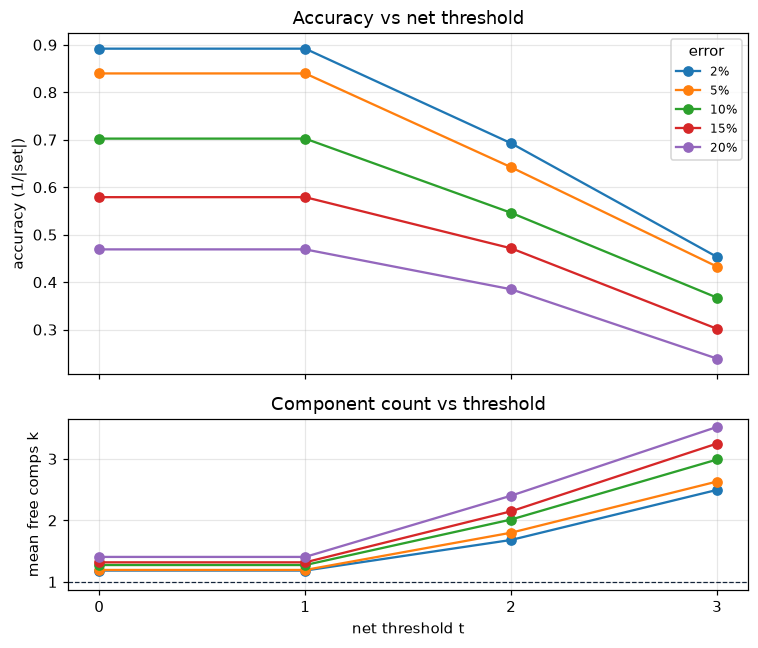

In [102]:
def seed_avg(sub, col):
    #media mediilor per seed :)) si std per seed
    per_seed = sub.groupby('seed')[col].mean()
    return per_seed.mean(), per_seed.std(ddof=1)

net = res[res['rule'] == 'net']
print('t |  accuracy  | mean k | frac disconnected')
for t in [0, 1, 2, 3]:
    cell = net[net['threshold'] == t]
    acc_m, acc_s = seed_avg(cell, 'pruned_acc')
    k_m, _ = seed_avg(cell, 'free_components')
    disc_m, _ = seed_avg(cell, 'disconnected')
    print(f'{t} | {acc_m:.3f}±{acc_s:.3f} | {k_m:.2f} | {disc_m:.2f}')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})
for er in ERROR_RATES:
    xs, ys, ks = [], [], []
    for t in [0, 1, 2, 3]:
        cell = net[(net['threshold'] == t) & (net['error_rate'] == er)]
        xs.append(t); ys.append(seed_avg(cell, 'pruned_acc')[0])
        ks.append(seed_avg(cell, 'free_components')[0])
    ax1.plot(xs, ys, '-o', label=f'{er:.0%}')
    ax2.plot(xs, ks, '-o')
ax1.set_ylabel('accuracy (1/|set|)'); ax1.legend(title='error', fontsize=8)
ax1.set_title('Accuracy vs net threshold'); ax1.grid(alpha=.3)
ax2.axhline(1, color='#14243A', ls='--', lw=.8)
ax2.set_ylabel('mean free comps k'); ax2.set_xlabel('net threshold t')
ax2.set_title('Component count vs threshold'); ax2.grid(alpha=.3)
ax2.set_xticks([0, 1, 2, 3]); fig.tight_layout(); plt.show()


### Edges kept vs accuracy (circuit-size trade-off) and the 'does it help?' check

The top-k curve is the resource trade-off: fewer edges means a smaller circuit.
The support rule is the one that *could* help by removing single-wrong-call edges,
so we check its seed-averaged gain over the full model, on connected datasets only.


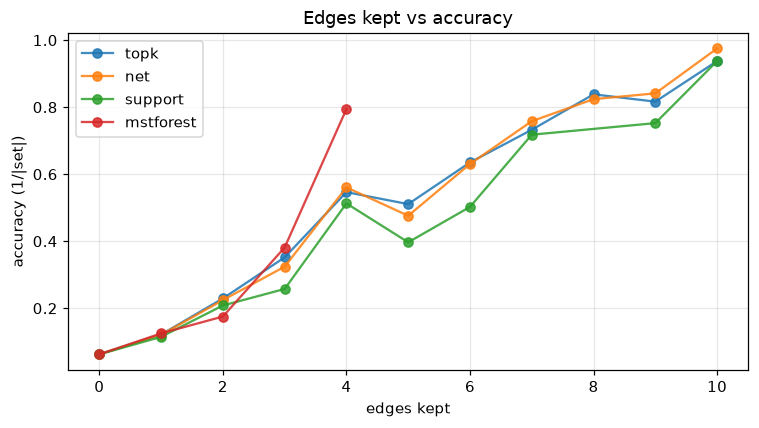


Support-rule gain (pruned - full), seed-averaged:
  error |   unconditioned (headline)   | connected-only (diagnostic)
     2% | -0.567 +/- 0.017  (hurts (clears std)) | +0.000 +/- 0.000
     5% | -0.502 +/- 0.038  (hurts (clears std)) | +0.000 +/- 0.000
    10% | -0.363 +/- 0.015  (hurts (clears std)) | -0.025 +/- 0.056
    15% | -0.261 +/- 0.023  (hurts (clears std)) | -0.108 +/- 0.328
    20% | -0.186 +/- 0.028  (hurts (clears std)) | -0.026 +/- 0.066

Ambiguity without disconnection: fraction of CONNECTED prunes that still tie = 0.068

Tie-edge fix check: mean free comps at t=0 (1.275) == t=1 (1.275) -> True


In [103]:
# Edges-kept vs accuracy, one line per rule (mstforest included).
fig, ax = plt.subplots(figsize=(7, 4))
for rule in ['topk', 'net', 'support', 'mstforest']:
    sub = res[res['rule'] == rule]
    g = sub.groupby('n_edges_kept')['pruned_acc'].mean()
    ax.plot(g.index, g.values, 'o-', label=rule, alpha=.85)
ax.set_xlabel('edges kept'); ax.set_ylabel('accuracy (1/|set|)')
ax.set_title('Edges kept vs accuracy')
ax.legend(); ax.grid(alpha=.3); fig.tight_layout(); plt.show()

# Does support pruning help? The HEADLINE is the unconditioned paired gain over
# EVERY dataset -- conditioning on "stayed connected" is selection bias, because
# the survivors are exactly the cases pruning could not hurt. We still print the
# connected-only number, but only as a diagnostic alongside the honest one.
print('\nSupport-rule gain (pruned - full), seed-averaged:')
print('  error |   unconditioned (headline)   | connected-only (diagnostic)')
sup_all = res[(res['rule'] == 'support') & (res['n_dropped'] > 0)]
sup_conn = sup_all[~sup_all['disconnected']]
for er in ERROR_RATES:
    cell_all = sup_all[sup_all['error_rate'] == er]
    cell_conn = sup_conn[sup_conn['error_rate'] == er]
    if len(cell_all):
        m, s = seed_avg(cell_all, 'gain')
        if m > s and m > 0:
            verdict = 'helps (clears std)'
        elif m < -s:
            verdict = 'hurts (clears std)'
        else:
            verdict = 'within noise'
        if len(cell_conn):
            mc, sc = seed_avg(cell_conn, 'gain')
            conn_str = f'{mc:+.3f} +/- {sc:.3f}'
        else:
            conn_str = 'n/a'
        print(f'  {er:5.0%} | {m:+.3f} +/- {s:.3f}  ({verdict:12s}) | {conn_str}')

print('\nAmbiguity without disconnection: fraction of CONNECTED prunes that still tie =',
      round((res[~res["disconnected"]]["n_tied"] > 1).mean(), 3))

# Sanity check on the fix: net t=0 and t=1 differ only by tie edges (net==0),
# which carry no coupling, so k and the disconnected fraction must now match.
net = res[res['rule'] == 'net']
k0, _ = seed_avg(net[net['threshold'] == 0], 'free_components')
k1, _ = seed_avg(net[net['threshold'] == 1], 'free_components')
print(f'\nTie-edge fix check: mean free comps at t=0 ({k0:.3f}) == t=1 ({k1:.3f}) ->',
      np.isclose(k0, k1))


### Conclusion

**Pruning weak edges does not improve phasing on this pairwise model; its clear,
repeatable effect is harm.** As the net threshold rises, accuracy falls exactly
where the component count climbs: raising t cuts bridges, the graph splits, and
no optimizer can recover a relationship the model no longer contains (the worked
example at scale). The baseline and the t=2 accuracy are stable to ~0.01 across
seeds, so this is a property of the model, not of one draw.

Connectivity is measured on the **active (net != 0) coupling graph**. A tie edge
(A == D) carries zero coupling, so it neither connects nor disconnects; counting
it would make net t=0 and t=1 look different (dropping ties) while the minima are
identical. With the fix, net t=0 and t=1 give the same component count and the
same accuracy, as they must.

Support pruning targets the edges a single wrong read creates. Judged honestly --
the **unconditioned** paired gain over every dataset, not just the ones that
stayed connected -- it is strongly negative at every error rate: conditioning on
survival was selection bias that hid the harm. The connected-only number is near
zero, but it only describes the minority of cases pruning failed to disconnect.
The net rule never helps either: a single error rarely flips an edge's sign, so
it only disconnects.

As a connectivity-preserving alternative we add **mstforest** (a maximum-weight
spanning forest on |A-D|): it keeps at most n-1 edges yet preserves exactly the
connectivity of the active graph, so it is the fairest way to shrink the circuit
without manufacturing disconnection. It is the rule to prefer when the goal is
fewer edges rather than better accuracy.

Two kinds of ambiguity stay separate: **introduced by pruning** (the graph
disconnects, or a net weight drops to a tie) versus **already in the data** (a
connected graph that still ties from contradictory votes or symmetry). A
connected graph can tie; a disconnected one always does, with at least 2^(k-1)
tied orientations.

*Limitations.* n=5 toy instances with a fixed set of strata and short synthetic
reads; the pairwise cost is not biological truth; tied-set size is reported, and
accuracy within a tie is 1/|set|, never a free win. Longer reads or larger n
could behave differently and would need their own sweep.
